In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/akshaymairal/store-item-demand-forecasting-challenge/sample_submission.csv
/kaggle/input/datasets/akshaymairal/store-item-demand-forecasting-challenge/test.csv
/kaggle/input/datasets/akshaymairal/store-item-demand-forecasting-challenge/train.csv


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("/kaggle/input/datasets/akshaymairal/store-item-demand-forecasting-challenge/train.csv", parse_dates=['date'])

df.shape

(913000, 4)

In [3]:
df.head(10)

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10
5,2013-01-06,1,1,12
6,2013-01-07,1,1,10
7,2013-01-08,1,1,9
8,2013-01-09,1,1,12
9,2013-01-10,1,1,9


In [4]:
df.groupby('store')['sales'].sum()

store
1     4315603
2     6120128
3     5435144
4     5012639
5     3631016
6     3627670
7     3320009
8     5856169
9     5025976
10    5360158
Name: sales, dtype: int64

In [5]:
df['date'].min(), df['date'].max()


(Timestamp('2013-01-01 00:00:00'), Timestamp('2017-12-31 00:00:00'))

In [6]:
df.isnull().sum()


date     0
store    0
item     0
sales    0
dtype: int64

In [7]:
import sqlite3
conn = sqlite3.connect("sales.db")
df.to_sql('sales', conn, if_exists='replace', index=False)

913000

In [8]:
pd.read_sql("SELECT date, store, item, sales FROM sales LIMIT 3", conn)

,date,store,item,sales
0,2013-01-01 00:00:00,1,1,13
1,2013-01-02 00:00:00,1,1,11
2,2013-01-03 00:00:00,1,1,14


In [9]:
pd.read_sql("""
Select SUBSTR(date, 1, 4) as Year, sum(sales) as Total_Sales from sales
group by Year""",conn)

,Year,Total_Sales
0,2013,7941243
1,2014,9135482
2,2015,9536887
3,2016,10357160
4,2017,10733740


In [10]:
pd.read_sql("""
select store , avg(sales) as average_sales from sales
group by store
order by avg(sales) desc""",conn)

,store,average_sales
0,2,67.033165
1,8,64.142048
2,3,59.530602
3,10,58.709288
4,9,55.049025
5,4,54.902946
6,1,47.268379
7,5,39.770164
8,6,39.733516
9,7,36.363735


In [11]:
pd.read_sql("""
select SUBSTR(date, 6, 2) as month , sum(sales) as total_sales from sales
group by month
order by total_sales desc """,conn)

,month,total_sales
0,07,5192393
1,06,4726911
2,05,4582437
3,08,4580655
4,11,4141356
5,04,4136467
6,09,4130457
7,10,3967520
8,03,3666182
9,12,3050808


In [12]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['dayofweek'] = df['date'].dt.dayofweek  

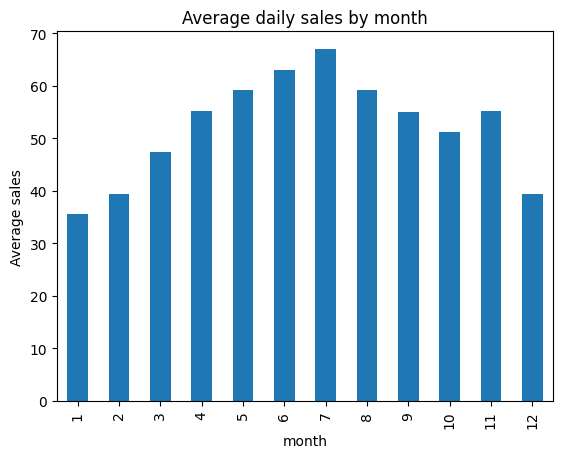

In [13]:
import matplotlib.pyplot as plt

df.groupby('month')['sales'].mean().plot(kind='bar', title='Average daily sales by month')
plt.ylabel('Average sales')
plt.show()

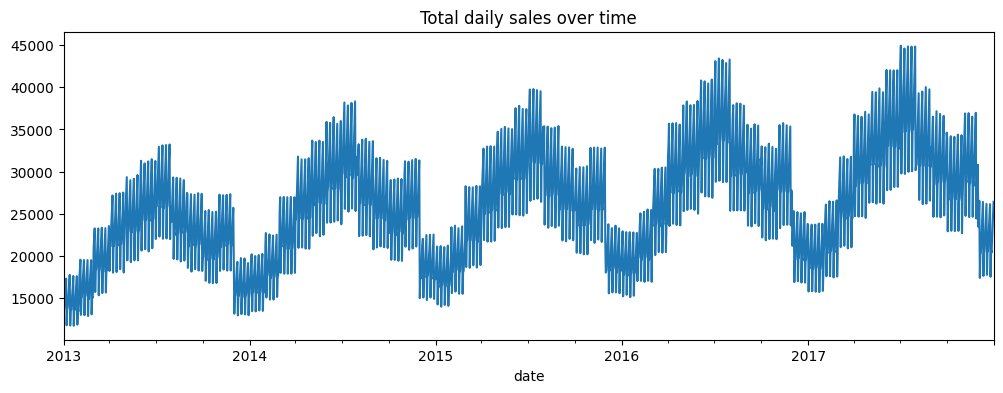

In [14]:
daily = df.groupby('date')['sales'].sum()
daily.plot(figsize=(12, 4), title='Total daily sales over time')
plt.show()

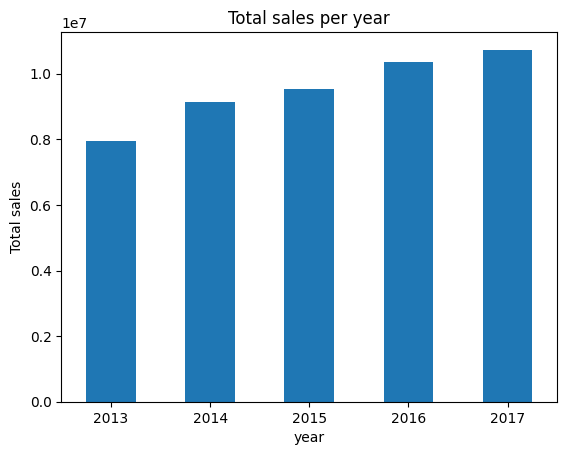

In [15]:
df.groupby('year')['sales'].sum().plot(kind='bar', title='Total sales per year')
plt.ylabel('Total sales')
plt.xticks(rotation=0)
plt.show()

In [16]:
train = df[df['date'] < '2017-01-01']    
test  = df[df['date'] >= '2017-01-01']   

train.shape, test.shape

((730500, 7), (182500, 7))

In [17]:
lag = df[['date', 'store', 'item', 'sales']].copy()

In [18]:
lag['date'] = lag['date'] + pd.Timedelta(days=364)

In [19]:
lag = lag.rename(columns={'sales': 'pred'})

In [20]:
lag.head()

,date,store,item,pred
0,2013-12-31,1,1,13
1,2014-01-01,1,1,11
2,2014-01-02,1,1,14
3,2014-01-03,1,1,13
4,2014-01-04,1,1,10


In [21]:
test_b = test.merge(lag, on=['date', 'store', 'item'], how='left')

In [22]:
test_b[['date', 'store', 'item', 'sales', 'pred']].head()

,date,store,item,sales,pred
0,2017-01-01,1,1,19,12
1,2017-01-02,1,1,15,12
2,2017-01-03,1,1,10,12
3,2017-01-04,1,1,16,16
4,2017-01-05,1,1,14,12


In [23]:
mae = (test_b['sales'] - test_b['pred']).abs().mean()
print("MAE =" , mae)

MAE = 8.553517808219178


In [24]:
avg_sales = test_b['sales'].mean()
print('Average daily sales:', round(avg_sales, 1))
print('Baseline error as % of sales:', round(mae / avg_sales * 100, 1), '%')

Average daily sales: 58.8
Baseline error as % of sales: 14.5 %


In [25]:
df = df.sort_values(['store', 'item', 'date']).reset_index(drop=True)

df['dayofyear'] = df['date'].dt.dayofyear
df['lag_364'] = df.groupby(['store', 'item'])['sales'].shift(364)

features = ['store', 'item', 'year', 'month', 'dayofyear', 'dayofweek', 'lag_364']


In [26]:
train = df[(df['date'] < '2017-01-01') & df['lag_364'].notnull()]
test  = df[df['date'] >= '2017-01-01']

X_train, y_train = train[features], train['sales']
X_test,  y_test  = test[features],  test['sales']

X_train.shape, X_test.shape

((548500, 7), (182500, 7))

In [27]:
train.head(10)

,date,store,item,sales,year,month,dayofweek,dayofyear,lag_364
364,2013-12-31,1,1,15,2013,12,1,365,13.0
365,2014-01-01,1,1,9,2014,1,2,1,11.0
366,2014-01-02,1,1,14,2014,1,3,2,14.0
367,2014-01-03,1,1,11,2014,1,4,3,13.0
368,2014-01-04,1,1,20,2014,1,5,4,10.0
369,2014-01-05,1,1,17,2014,1,6,5,12.0
370,2014-01-06,1,1,14,2014,1,0,6,10.0
371,2014-01-07,1,1,11,2014,1,1,7,9.0
372,2014-01-08,1,1,12,2014,1,2,8,12.0
373,2014-01-09,1,1,17,2014,1,3,9,9.0


In [28]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_test)


mae_lr = mean_absolute_error(y_test, lr_pred)

print('Baseline MAE:          ', round(mae, 2))
print('Linear Regression MAE: ', round(mae_lr, 2))

Baseline MAE:           8.55
Linear Regression MAE:  8.42


In [29]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

model = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6,
                     random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

pred = model.predict(X_test)
mae_xgb = mean_absolute_error(y_test, pred)

print('Baseline MAE:', round(mae, 2))
print('Linear Regression MAE: ', round(mae_lr, 2))
print('XGBoost MAE: ', round(mae_xgb, 2))


Baseline MAE: 8.55
Linear Regression MAE:  8.42
XGBoost MAE:  6.93


In [30]:
print('Actual average:   ', round(y_test.mean(), 1))
print('Predicted average:', round(pred.mean(), 1))

Actual average:    58.8
Predicted average: 58.7


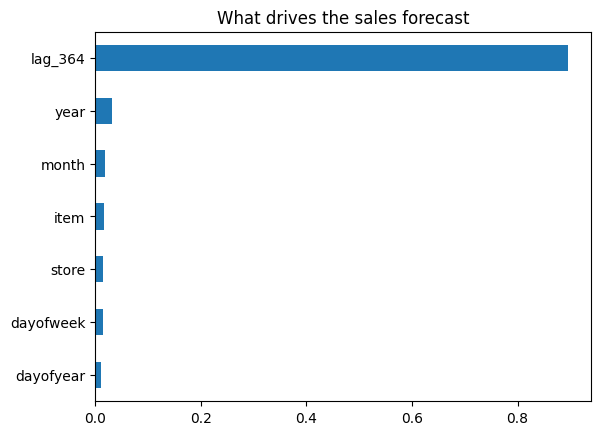

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', title='What drives the sales forecast')
plt.show()

In [32]:
res = pd.DataFrame({
    'store': X_test['store'],
    'item': X_test['item'],
    'actual': y_test,
    'pred': pred
})

res['abs_err'] = abs(res['pred'] - res['actual'])

res['error'] = res['pred'] - res['actual']

business_analysis = (
    res.groupby(['store', 'item'])
    .agg(
        Actual_Demand=('actual', 'sum'),
        Forecast_Demand=('pred', 'sum'),
        Total_Abs_Error=('abs_err', 'sum'),
        Average_Error=('error', 'mean')
    )
    .reset_index()
)



numeric_cols = business_analysis.select_dtypes(
    include='number'
).columns

business_analysis[numeric_cols] = (
    business_analysis[numeric_cols].round(0).astype(int)
)

business_analysis = (
    business_analysis
    .sort_values('Total_Abs_Error', ascending=False)
    .reset_index(drop=True)
)

business_analysis.index = business_analysis.index + 1
business_analysis.index.name = 'Rank'

business_analysis.head(10).style.format('{:,.0f}').set_caption(
    'Top 10 Store-Item Combinations by Forecasting Error'
)

,store,item,Actual_Demand,Forecast_Demand,Total_Abs_Error,Average_Error
Rank,,,,,,
1,2,18,"44,776","42,883","3,919",-5
2,2,28,"46,133","44,517","3,837",-4
3,2,38,"42,486","40,683","3,836",-5
4,8,28,"44,486","42,317","3,793",-6
5,8,15,"44,431","42,600","3,716",-5
6,2,45,"42,644","41,108","3,695",-4
7,8,13,"42,641","40,959","3,548",-5
8,4,18,"36,464","35,507","3,522",-3
9,2,13,"44,305","42,898","3,513",-4


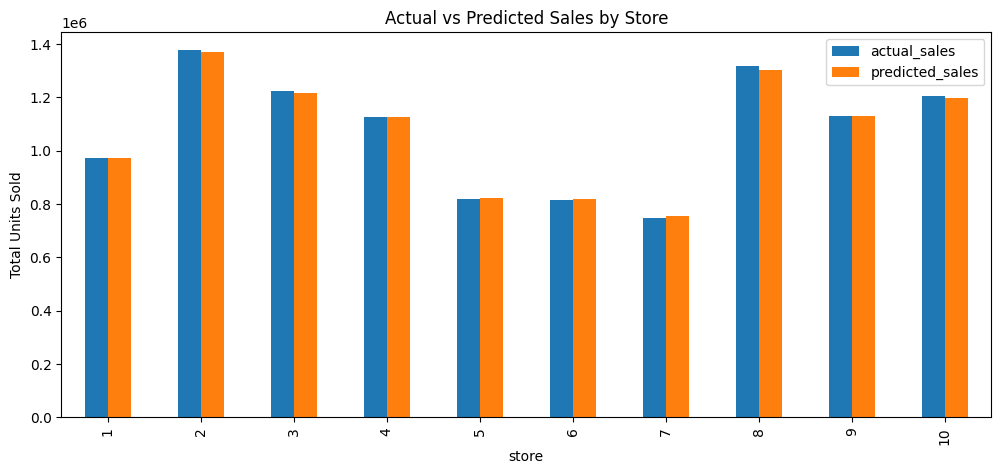

In [33]:
store_demand = res.groupby('store').agg(
    actual_sales=('actual', 'sum'),
    predicted_sales=('pred', 'sum')
)

store_demand.plot(
    kind='bar',
    figsize=(12, 5),
    title='Actual vs Predicted Sales by Store'
)

plt.ylabel('Total Units Sold')
plt.show()